# Redes: variables al corte y fuga de información

## Resumen de la ejecución

Datos sintéticos; resultados de esta ejecución:

- **Primer conteo válido de campaña:** 0
- **Grado retrospectivo inválido:** 24
- **Invariancia a eventos futuros:** True

Los supuestos, límites y contraejemplos se explican junto a cada experimento.

## Objetivo y método

¿Cómo distinguir reutilización observada de conexiones que solo se conocen después? Construimos enlaces sintéticos reales, agregados bitemporales y un contraejemplo retrospectivo.

### Supuestos y población

Un enlace tiene application_id, entity, event_at y available_at. No se usan etiquetas de vecinos. Compartir un dispositivo puede ser legítimo; el conteo no es una probabilidad de fraude.

Todos los datos son sintéticos. Las cifras ilustran mecanismos y no constituyen desempeño observado en una entidad. Fecha de desarrollo: 21 de octubre de 2026.

## Entorno reproducible

Ejecutar en orden, desde esta carpeta o una subcarpeta de la línea de fraude. La semilla y los parámetros quedan en las celdas; no se consulta internet ni se leen datos de clientes.

In [1]:
%matplotlib inline
from pathlib import Path
import sys, math, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from sklearn.metrics import average_precision_score, brier_score_loss
base = next(p for p in [Path.cwd(), *Path.cwd().parents] if p.name == 'fraud-and-anomaly-research')
sys.path.insert(0, str(base / 'loss-minimization-engine'))
from src.engine import Case, Action, Scenario, optimize, expected_cost, shared_entity_count
rng = np.random.default_rng(20261021)
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams.update({'figure.figsize': (8, 4.5), 'figure.dpi': 120, 'font.size': 11,
                     'axes.spines.top': False, 'axes.spines.right': False, 'grid.alpha': .25})
BLUE, TEAL, GOLD, PURPLE = '#386A96', '#217A72', '#B37D2E', '#73579D'
pd.options.display.float_format = '{:,.4f}'.format

No event loop hook running.


## 1. Construir el grafo temporal


$$N_v(t,w)=\left|\{i: v_i=v,\ t-w\le e_i<t,\ a_i\le t,\ i\ne i_{actual}\}\right|.$$

$e_i$ es fecha del hecho y $a_i$ disponibilidad. Se cuentan solicitudes distintas y se excluye la solicitud actual. Un dato tardío no pertenece al pasado disponible.

,day,entity,causal_count,invalid_retrospective_degree
55,55,campaign-device,0,24
56,56,campaign-device,1,24
57,57,campaign-device,2,24
58,58,campaign-device,3,24
59,59,campaign-device,4,24
60,60,campaign-device,5,24
61,61,campaign-device,6,24
62,62,campaign-device,7,24


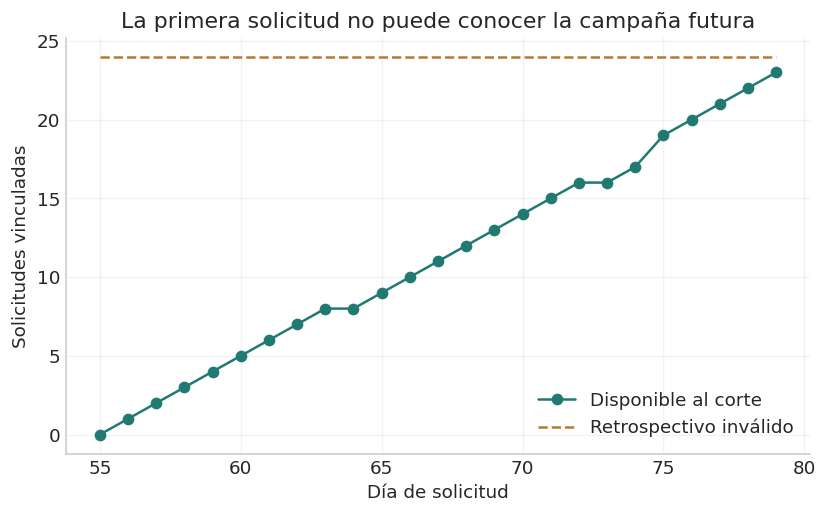

In [2]:
links=[]
for i in range(120):
    entity='campaign-device' if 55<=i<80 else ('shared-hub' if i%5==0 else f'private-{i}')
    delay=12 if i%9==0 else 0
    links.append({'application_id':f'app-{i}','entity':entity,'event_at':float(i),'available_at':float(i+delay)})
rows=[]
for link in links:
    t=link['event_at'];entity=link['entity']
    safe=shared_entity_count(links,entity,t,link['application_id'],window=30)
    # Deliberately invalid: future degree from the complete retrospective graph.
    future_degree=len({z['application_id'] for z in links if z['entity']==entity and z['application_id']!=link['application_id']})
    rows.append({'day':int(t),'entity':entity,'causal_count':safe,'invalid_retrospective_degree':future_degree})
graph_data=pd.DataFrame(rows)
display(graph_data[graph_data['entity']=='campaign-device'].head(8))
fig,ax=plt.subplots();subset=graph_data[graph_data['entity']=='campaign-device']
ax.plot(subset['day'],subset['causal_count'],label='Disponible al corte',color=TEAL,marker='o')
ax.plot(subset['day'],subset['invalid_retrospective_degree'],label='Retrospectivo inválido',color=GOLD,linestyle='--')
ax.set(xlabel='Día de solicitud',ylabel='Solicitudes vinculadas',title='La primera solicitud no puede conocer la campaña futura');ax.legend();plt.show()

La serie retrospectiva incluye hechos posteriores y una ventana distinta. Se muestra como contraejemplo inválido y nunca alimenta un resultado de desempeño. Las diferencias no prueban por sí solas qué modelo detecta mejor.

## 2. Hubs legítimos y señales insuficientes


Un grado alto puede tener varias explicaciones. Una normalización propuesta es $R_v=N_v/\log(2+D_v)$, donde $D_v$ es grado histórico disponible. Atenúa infraestructura compartida, pero también puede atenuar campañas: debe validarse, no presumirse correcta.

,solicitudes,conteo_medio,conteo_maximo
entity,,,
campaign-device,25,11.2800,23
shared-hub,19,3.5789,6


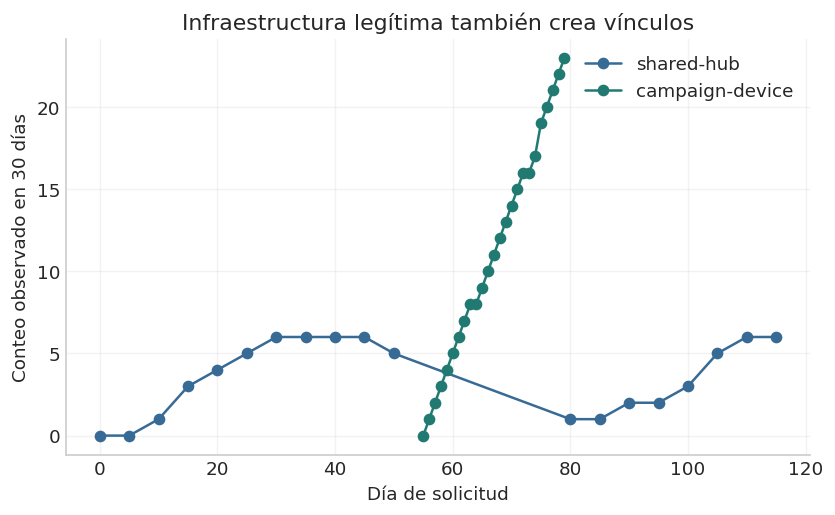

In [3]:
summary=graph_data[graph_data['entity'].isin(['shared-hub','campaign-device'])].groupby('entity').agg(solicitudes=('day','size'),conteo_medio=('causal_count','mean'),conteo_maximo=('causal_count','max'))
display(summary)
fig,ax=plt.subplots();
for entity,color in [('shared-hub',BLUE),('campaign-device',TEAL)]:
    subset=graph_data[graph_data['entity']==entity]
    ax.plot(subset['day'],subset['causal_count'],marker='o',label=entity,color=color)
ax.set(xlabel='Día de solicitud',ylabel='Conteo observado en 30 días',title='Infraestructura legítima también crea vínculos');ax.legend();plt.show()

El hub se etiqueta legítimo por construcción del ejemplo, no por inferencia del detector. Un solo conteo no distingue intención, titulares ni destino final de fondos. Se requieren fuentes y adjudicación independientes.

## 3. Eventos tardíos y deduplicación


La condición $a_i\le t$ se vuelve visible con un enlace antiguo que llega tarde. Una duplicación física de fila no debe duplicar la entidad lógica.

In [4]:
late={'application_id':'late-app','entity':'test-device','event_at':5.,'available_at':20.}
observations=[shared_entity_count([late,late],'test-device',float(t),window=30) for t in [10,19,20,21]]
display(pd.DataFrame({'corte':[10,19,20,21],'solicitudes_distintas':observations}))
future={'application_id':'future','entity':'campaign-device','event_at':200.,'available_at':200.}
before=shared_entity_count(links,'campaign-device',65.,'app-65')
after=shared_entity_count(links+[future],'campaign-device',65.,'app-65')

,corte,solicitudes_distintas
0,10,0
1,19,0
2,20,1
3,21,1


La igualdad al instante de disponibilidad está permitida; la ventana del hecho excluye la solicitud en t. No se afirma que el ejemplo implemente resolución de identidad, GNN ni separación de campañas fuera de muestra.

## Comprobaciones y límites

Las identidades y contraejemplos siguientes son parte del experimento; no verifican desempeño productivo.

In [5]:
assert before==after
assert observations==[0,0,1,1]
assert graph_data.loc[55,'causal_count']==0
assert graph_data.loc[55,'invalid_retrospective_degree']>0

## Resultados computados

In [6]:
metrics = {'Primer conteo válido de campaña': int(graph_data.loc[55,'causal_count']), 'Grado retrospectivo inválido': int(graph_data.loc[55,'invalid_retrospective_degree']), 'Invariancia a eventos futuros': bool(before==after)}
print("LAB_METRICS:" + json.dumps(metrics, ensure_ascii=False))

LAB_METRICS:{"Primer conteo válido de campaña": 0, "Grado retrospectivo inválido": 24, "Invariancia a eventos futuros": true}


## Ideas y preguntas para continuar

1. Construir variables de cuenta destino y dispositivo por separado.
2. Evaluar campañas nuevas con partición de componentes y fecha.
3. Medir cuánto cambia la señal al rotar entidades y perder enlaces.
4. Incorporar confianza del enlace y ambigüedad de resolución antes de una GNN.

## Fuentes y relación con el proyecto

- Primitivo local: `shared_entity_count` en el motor.
- [Duan et al., grafos temporales en fraude transaccional](https://arxiv.org/abs/2402.14708): antecedente; no valida este ejemplo de originación.

Consultar también `../README.md` y `../../MODEL_AND_LOSS_METHODS.md`.